# بسم الله الرحمن الرحيم

--------------------------------------------------

# Problem Statement

#### For companies like Lending Club correctly predicting whether or not a loan will be a default is very important. In this project, using the historical data from 2007 to 2015, we will build a deep learning model to predict the chance of default for future loans. This dataset is highly imbalanced and includes a lot of features that makes this problem more challenging.

----------------------------

## Domain:
#### Finance
-----------------------
## Analysis to be done:
#### Perform data preprocessing and build a deep learning prediction model.
----------------------

# Content:

## Dataset columns and definition:



**credit.policy:**
1 if the customer meets the credit underwriting criteria of LendingClub.com, and 0 otherwise.

**purpose:**
The purpose of the loan (takes values "credit_card", "debt_consolidation", "educational", "major_purchase", "small_business", and "all_other").

**int.rate:**
The interest rate of the loan, as a proportion (a rate of 11% would be stored as 0.11). Borrowers judged by LendingClub.com to be more risky are assigned higher interest rates.

**installment:**
The monthly installments owed by the borrower if the loan is funded.

**log.annual.inc:**
The natural log of the self-reported annual income of the borrower.

**dti:**
The debt-to-income ratio of the borrower (amount of debt divided by annual income).

**fico:**
The FICO credit score of the borrower.

**days.with.cr.line:**
The number of days the borrower has had a credit line.

**revol.bal:**
The borrower's revolving balance (amount unpaid at the end of the credit card billing cycle).

**revol.util:**
The borrower's revolving line utilization rate (the amount of the credit line used relative to total credit available).

**inq.last.6mths:**
The borrower's number of inquiries by creditors in the last 6 months.

**delinq.2yrs:**
The number of times the borrower had been 30+ days past due on a payment in the past 2 years.

**pub.rec:**
The borrower's number of derogatory public records (bankruptcy filings, tax liens, or judgments).

-------------------------------------------------------


## Steps to perform:

Perform exploratory data analysis and feature engineering and then apply feature engineering. Follow up with a deep learning model to predict whether or not the loan will be default using the historical data.

--------------------------------


## Tasks:

1.     Feature Transformation: Transform categorical values into numerical values (discrete)

2.     Exploratory data analysis of different factors of the dataset.

3.     Additional Feature Engineering: You will check the correlation between features and will drop those features which have a strong correlation. This will help reduce the number of features and will leave you with the most relevant features

4.     Modeling: After applying EDA and feature engineering, you are now ready to build the predictive models. In this part, you will create a deep learning model using Keras with Tensorflow backend

---------------------------

-----------------------

In [ ]:
#Importing Libraries ✔
#Reading dataset ✔
#Understanding the dataset info, shape, unique ✔
#Null values and duplicates ✔
#Skewness and distribution ✔
#Visualization distribution, count, box ✔
#training the model ✔
#testing the model ✔
# evaluating the model ✔

--------------------------

In [1]:
# import libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import scipy.stats as stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
import warnings

In [3]:
# Importing tensorflow and Keras libraries and packages
import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LeakyReLU, PReLU, ELU
from keras.layers import Dropout

# EDA

In [5]:
# reading data
data = pd.read_csv(r"loan_data.csv")

In [10]:
data.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   object 
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), object(1)
memory usage: 1.0+ MB


In [12]:
data.shape

(9578, 14)

In [13]:
data.describe()

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000


In [14]:
# function for unique values
def get_unique(data):
    for col in data:
        print(col, ':', data[col].unique(), '\n')

In [16]:
get_unique(data)

credit.policy : [1 0] 

purpose : ['debt_consolidation' 'credit_card' 'all_other' 'home_improvement'
 'small_business' 'major_purchase' 'educational'] 

int.rate : [0.1189 0.1071 0.1357 0.1008 0.1426 0.0788 0.1496 0.1114 0.1134 0.1221
 0.1347 0.1324 0.0859 0.0714 0.0863 0.1103 0.1317 0.0894 0.1039 0.1513
 0.08   0.1355 0.1229 0.0901 0.0743 0.1375 0.0807 0.1028 0.087  0.1122
 0.0996 0.0933 0.0838 0.0775 0.1059 0.1596 0.1154 0.1343 0.1249 0.0964
 0.1186 0.1501 0.128  0.1091 0.1217 0.1533 0.0712 0.1438 0.1565 0.1467
 0.1312 0.147  0.1407 0.1014 0.1046 0.133  0.0983 0.1393 0.092  0.1236
 0.1362 0.1078 0.1583 0.1109 0.1141 0.1267 0.1204 0.0951 0.1172 0.1299
 0.1488 0.152  0.1425 0.1836 0.1615 0.06   0.0832 0.1261 0.0945 0.1197
 0.1387 0.0976 0.1292 0.0737 0.0768 0.1166 0.1418 0.1545 0.1482 0.1703
 0.145  0.1671 0.1576 0.1608 0.164  0.1734 0.1051 0.157  0.1222 0.1273
 0.1379 0.1253 0.1128 0.1286 0.1287 0.097  0.1001 0.1538 0.1191 0.1254
 0.1159 0.138  0.1096 0.1064 0.1349 0.1033 0.1475 0.160

In [17]:
#null values
data.isnull().sum()

,0
credit.policy,0
purpose,0
int.rate,0
installment,0
log.annual.inc,0
dti,0
fico,0
days.with.cr.line,0
revol.bal,0
revol.util,0


In [18]:
# duplicated values
data.duplicated().sum()

0

In [7]:
# treating catigorical data using get_dummies
Purpose = pd.get_dummies(data["purpose"], drop_first = True)
data = pd.concat([data, Purpose], axis=1)
data = data.drop(['purpose'], axis=1)

# Feature Engineering

In [6]:
# Most significant features
corr = data.corr().round(2)
high= corr['credit.policy'][(corr['credit.policy'] >=0.5) | (corr['credit.policy'] <= -0.5)].index.tolist()
print("High correlatons: \n", high)

High correlatons: 
 ['credit.policy', 'inq.last.6mths']


In [9]:

class ChiSquare:
#Function to determine p-value and perform chi-square test
    def __init__(self, dataframe):
        self.data = dataframe
        self.p = None #P-Value
        self.chi2 = None #Chi-square Test Statistic
        self.dof = None

        self.dfObserved = None
        self.dfExpected = None
        global sig_data
        sig_data = list()

#Function to print the results of p-value and chi-square test
    def _print_chisquare_result(self, colX, alpha):

        result = ""
        if self.p<alpha:
            result="{0} is IMPORTANT for Prediction".format(colX)
            sig_data.append(colX)
        else:
            result="{0} is NOT an important predictor. (Discard {0} from model)".format(colX)
        print(result)

#Function to determine chi-square and p-value less than or equal to 0.05
    def TestIndependence(self,colX,colY, alpha=0.05):
        X = self.data[colX].astype(str)
        Y = self.data[colY].astype(str)

        self.dfObserved = pd.crosstab(Y,X)
        chi2, p, dof, expected = stats.chi2_contingency(self.dfObserved.values)
        self.p = p
        self.chi2 = chi2
        self.dof = dof

        self.dfExpected = pd.DataFrame(expected, columns=self.dfObserved.columns, index = self.dfObserved.index)

        self._print_chisquare_result(colX,alpha)


In [22]:
data.columns

Index(['credit.policy', 'int.rate', 'installment', 'log.annual.inc', 'dti',
       'fico', 'days.with.cr.line', 'revol.bal', 'revol.util',
       'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid',
       'credit_card', 'debt_consolidation', 'educational', 'home_improvement',
       'major_purchase', 'small_business'],
      dtype='object')

In [11]:
#Initializing ChiSquare Class
st = ChiSquare(data)
#Perform Feature Selection
testColumns = ['credit.policy', 'int.rate', 'installment', 'log.annual.inc', 'dti',
       'fico', 'days.with.cr.line', 'revol.bal', 'revol.util',
       'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid',
       'credit_card', 'debt_consolidation', 'educational', 'home_improvement',
       'major_purchase', 'small_business']
for var in testColumns:
    st.TestIndependence(colX=var,colY="credit.policy" )

credit.policy is IMPORTANT for Prediction
int.rate is IMPORTANT for Prediction
installment is IMPORTANT for Prediction
log.annual.inc is NOT an important predictor. (Discard log.annual.inc from model)
dti is IMPORTANT for Prediction
fico is IMPORTANT for Prediction
days.with.cr.line is IMPORTANT for Prediction
revol.bal is NOT an important predictor. (Discard revol.bal from model)
revol.util is IMPORTANT for Prediction
inq.last.6mths is IMPORTANT for Prediction
delinq.2yrs is IMPORTANT for Prediction
pub.rec is IMPORTANT for Prediction
not.fully.paid is IMPORTANT for Prediction
credit_card is NOT an important predictor. (Discard credit_card from model)
debt_consolidation is NOT an important predictor. (Discard debt_consolidation from model)
educational is IMPORTANT for Prediction
home_improvement is NOT an important predictor. (Discard home_improvement from model)
major_purchase is IMPORTANT for Prediction
small_business is NOT an important predictor. (Discard small_business from model

In [13]:
# list of significant features:
sig_data

['credit.policy',
 'int.rate',
 'installment',
 'dti',
 'fico',
 'days.with.cr.line',
 'revol.util',
 'inq.last.6mths',
 'delinq.2yrs',
 'pub.rec',
 'not.fully.paid',
 'educational',
 'major_purchase']

In [15]:
sig_data = data[['credit.policy',
 'int.rate',
 'installment',
 'dti',
 'fico',
 'days.with.cr.line',
 'revol.util',
 'inq.last.6mths',
 'delinq.2yrs',
 'pub.rec',
 'not.fully.paid',
 'educational',
 'major_purchase']].copy()

In [17]:
sig_data.head()

,credit.policy,int.rate,installment,dti,fico,days.with.cr.line,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,educational,major_purchase
0,1,0.1189,829.10,19.48,737,5639.958333,52.1,0,0,0,0,False,False
1,1,0.1071,228.22,14.29,707,2760.000000,76.7,0,0,0,0,False,False
2,1,0.1357,366.86,11.63,682,4710.000000,25.6,1,0,0,0,False,False
3,1,0.1008,162.34,8.10,712,2699.958333,73.2,1,0,0,0,False,False
4,1,0.1426,102.92,14.97,667,4066.000000,39.5,0,1,0,0,False,False


# Data Visualization

In [19]:
skew = sig_data.skew(axis =0)
skew

credit.policy       -1.539621
int.rate             0.164420
installment          0.912522
dti                  0.023941
fico                 0.471260
days.with.cr.line    1.155748
revol.util           0.059985
inq.last.6mths       3.584151
delinq.2yrs          6.061793
pub.rec              5.126434
not.fully.paid       1.854592
educational          4.996915
major_purchase       4.355613
dtype: float64

credit.policy -1.5396214403439585


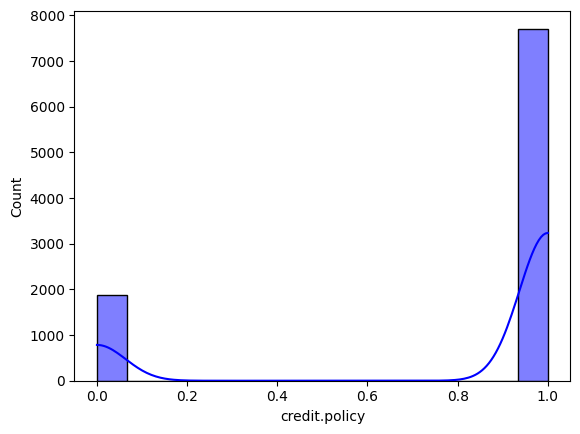

int.rate 0.16441991354447316


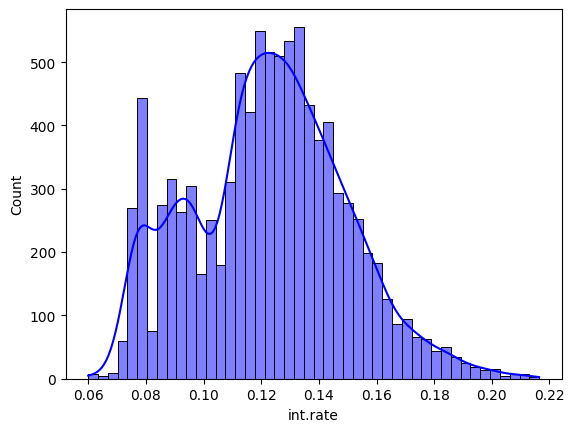

installment 0.9125224624010233


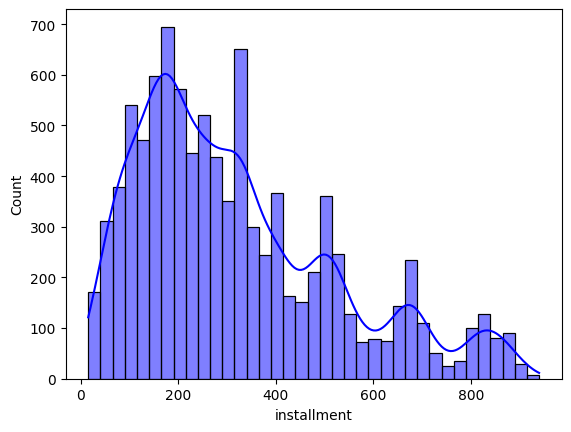

dti 0.023941022949340144


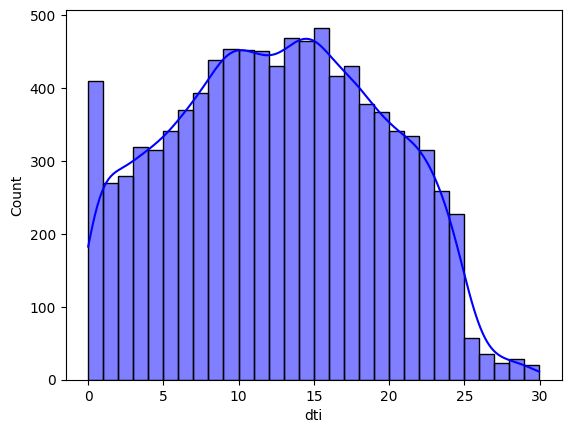

fico 0.4712597399323796


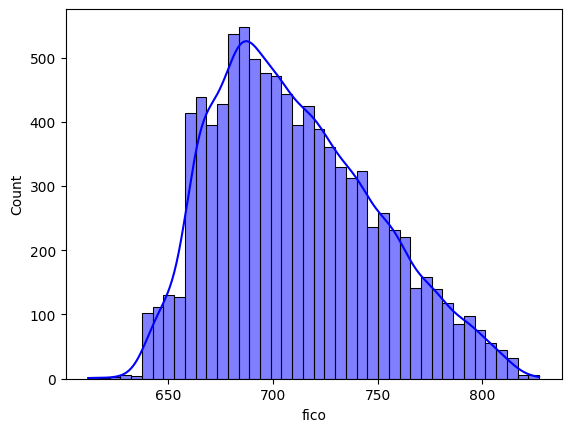

days.with.cr.line 1.1557482270969546


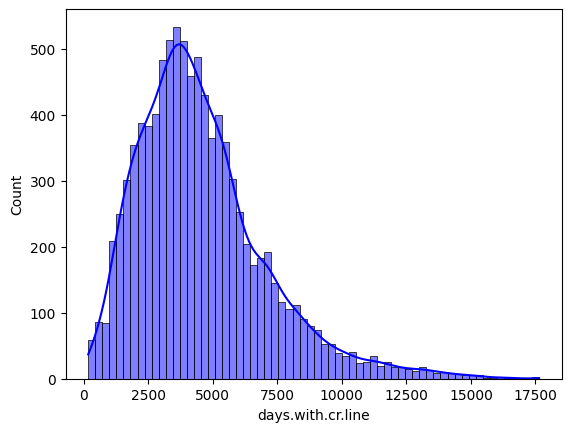

revol.util 0.05998544258288086


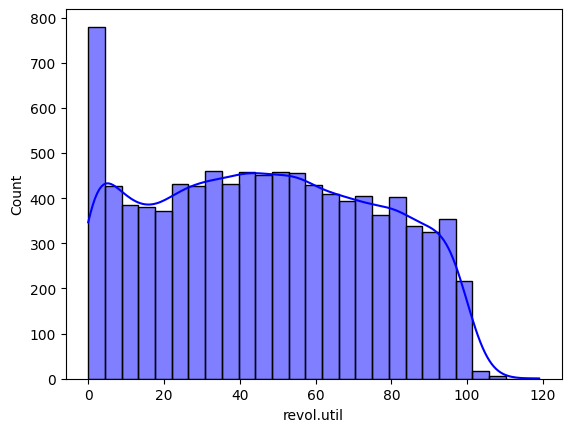

inq.last.6mths 3.5841508563803304


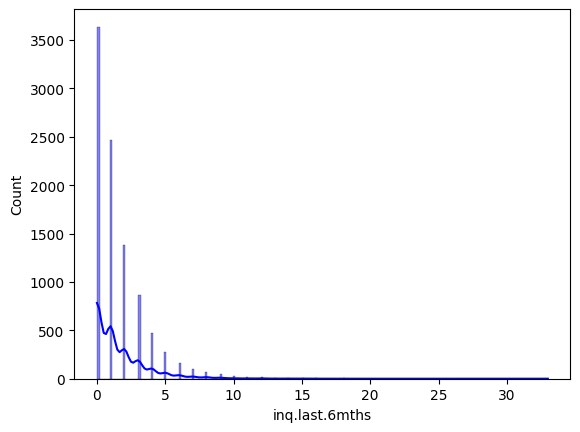

delinq.2yrs 6.0617932757524455


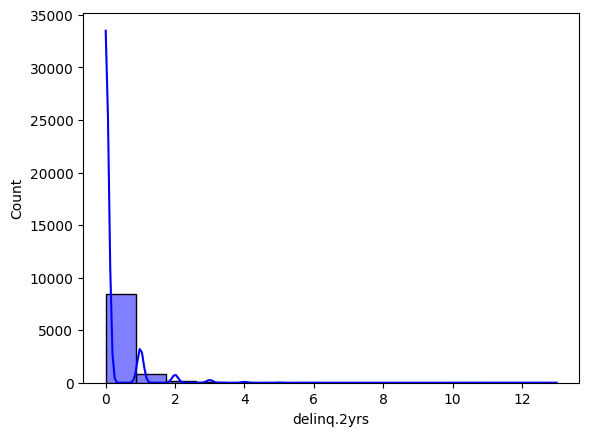

pub.rec 5.126434459765956


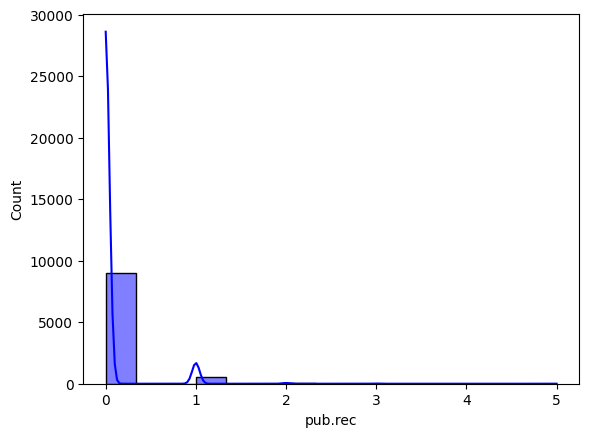

not.fully.paid 1.854591704621826


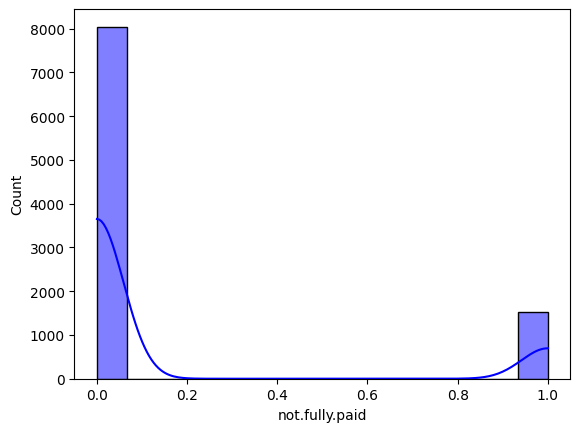

educational 4.996915055702888


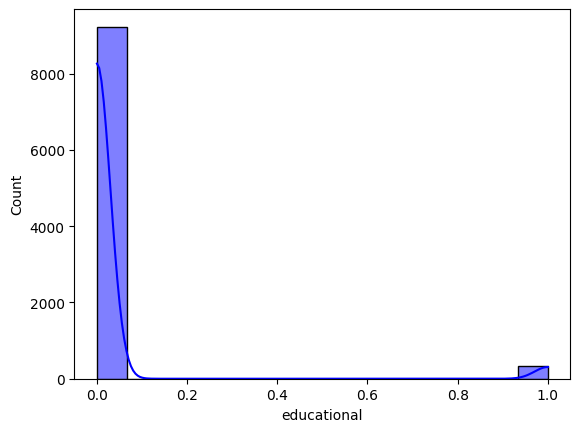

major_purchase 4.355613468431223


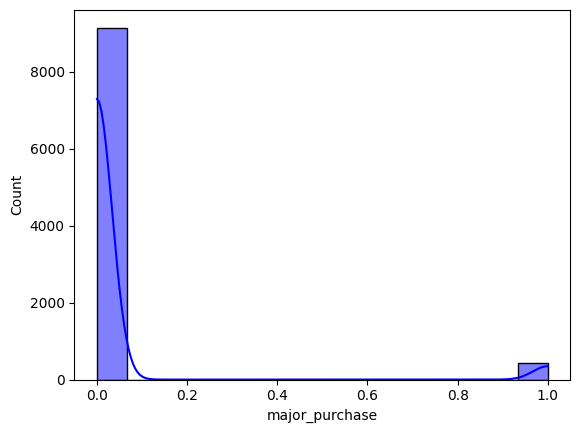

In [28]:
for col in sig_data:
    print(col, skew[col])
    sns.histplot(sig_data[col], color = 'blue',  kde=True)
    plt.show()

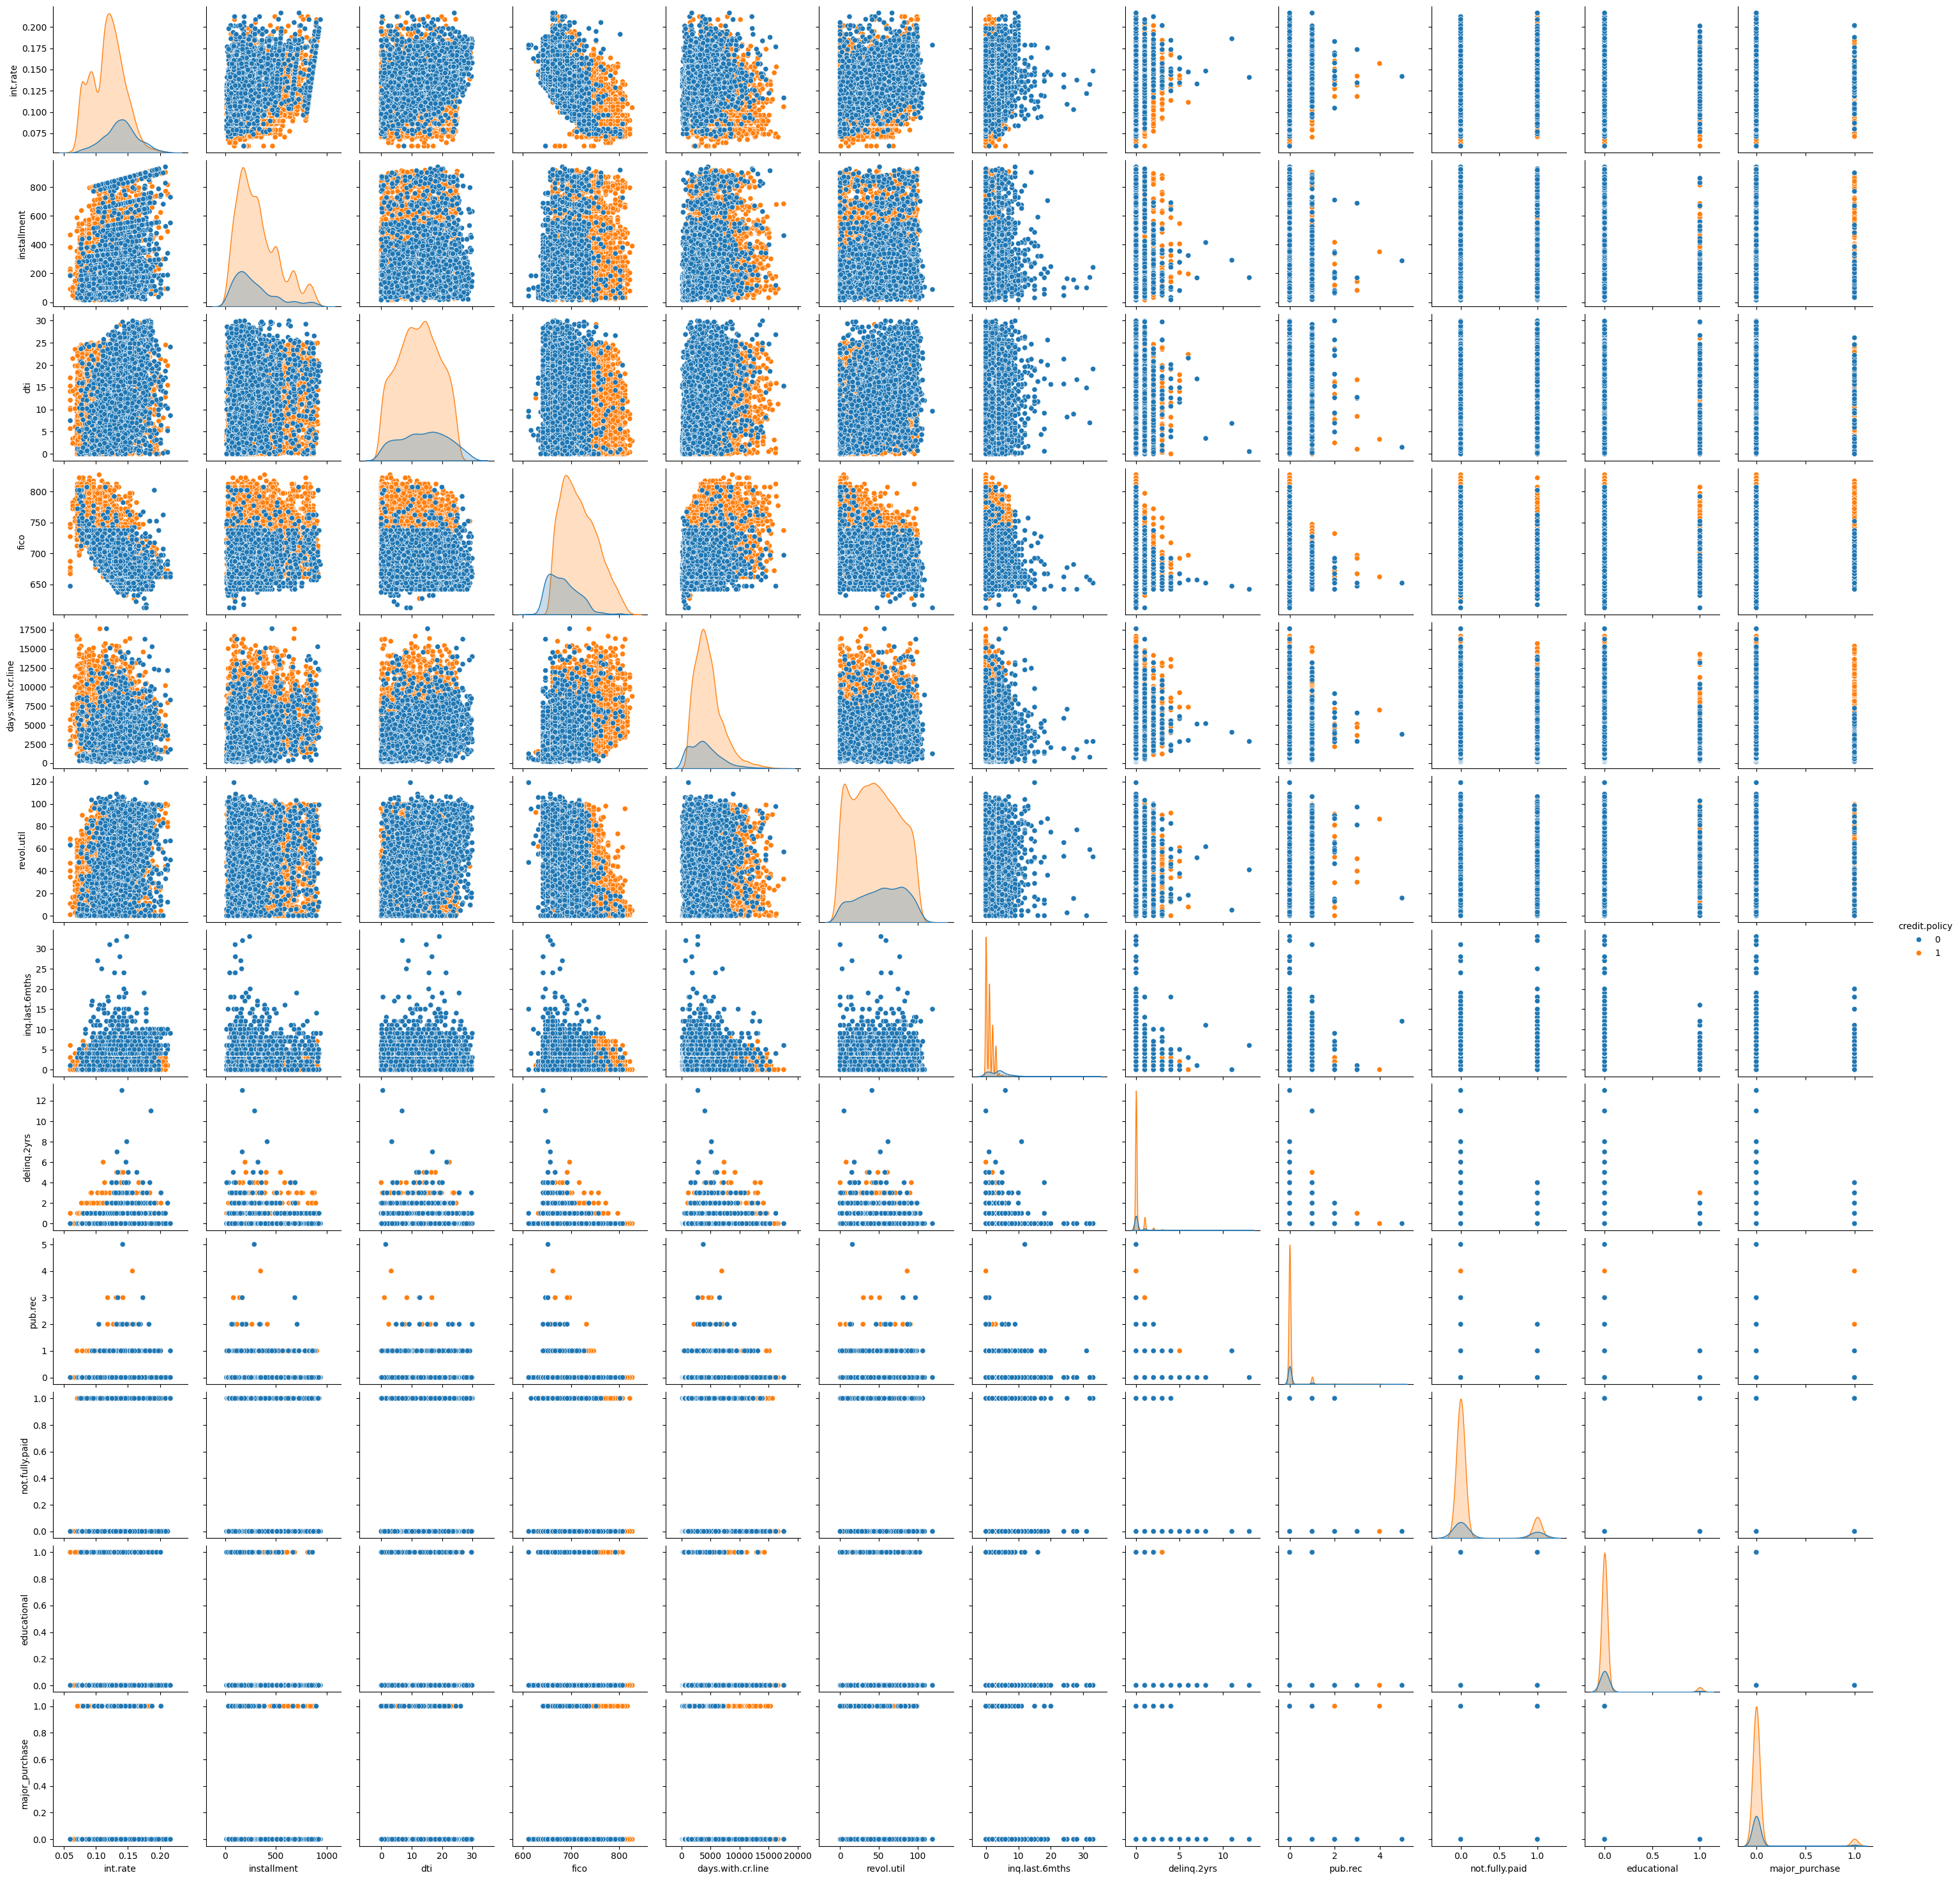

In [68]:
sns.pairplot(sig_data, hue='credit.policy', height=2.5)

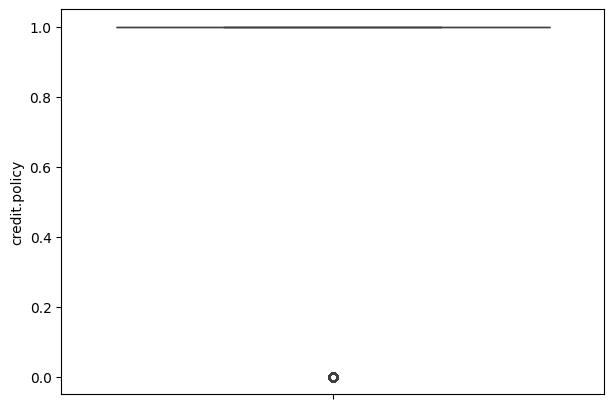

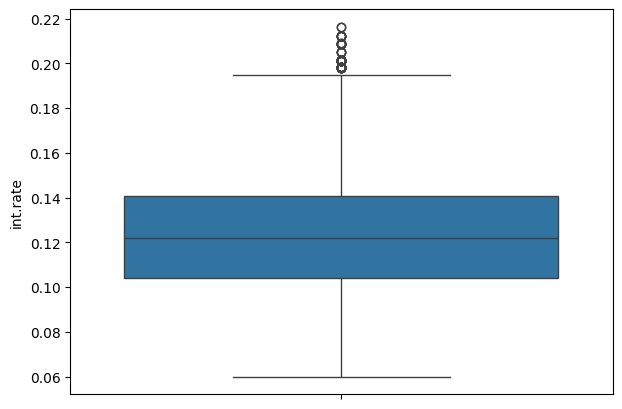

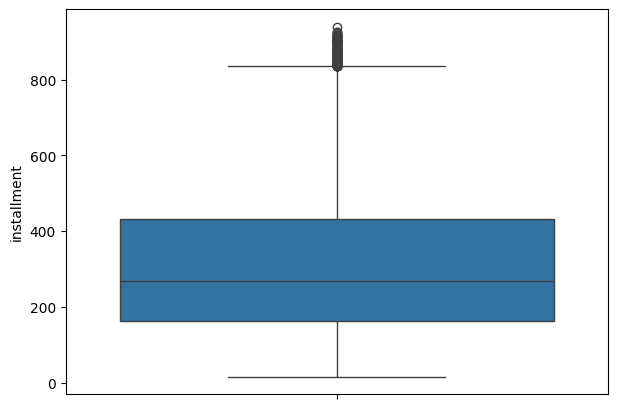

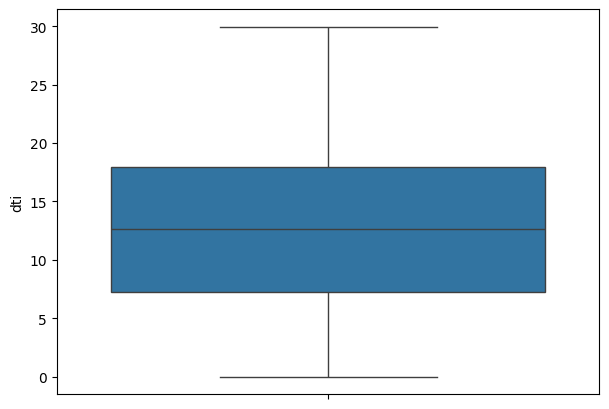

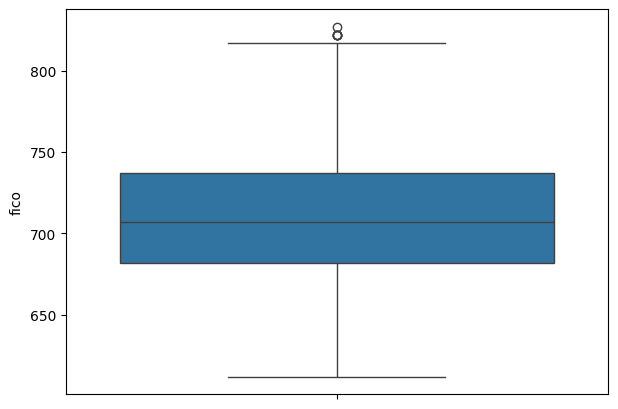

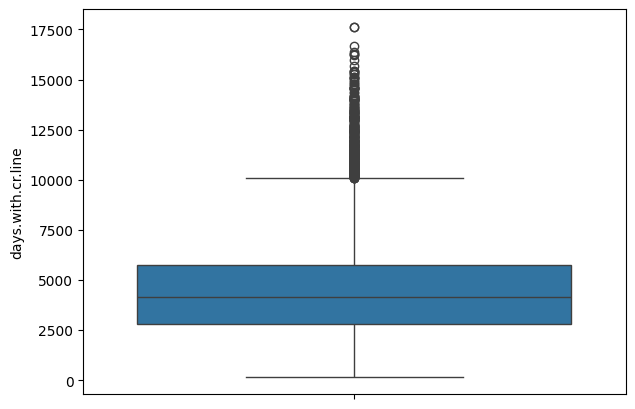

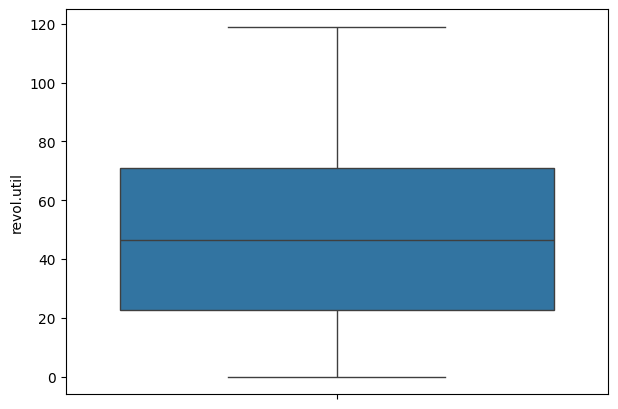

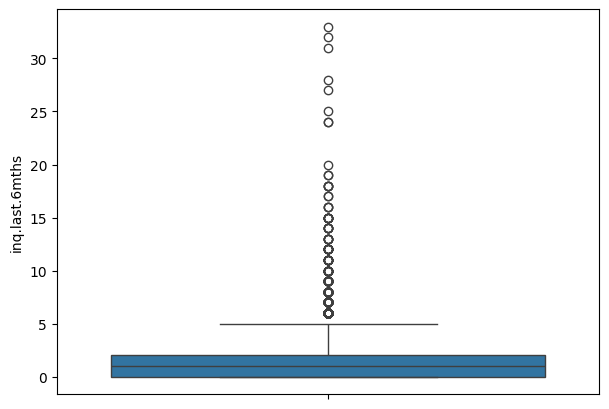

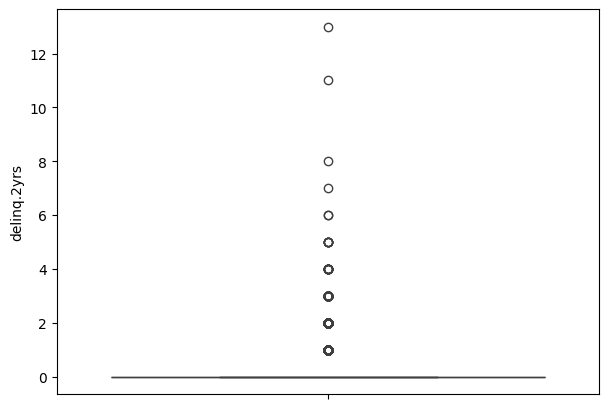

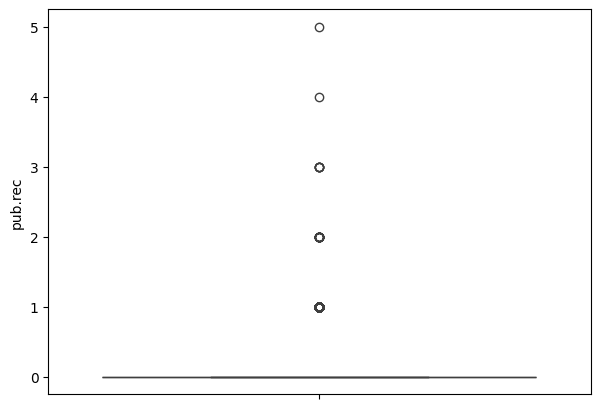

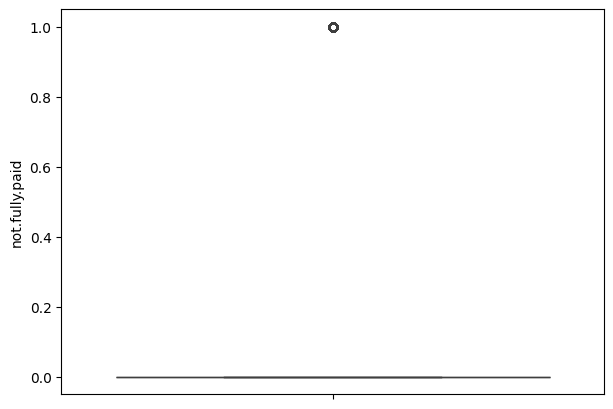

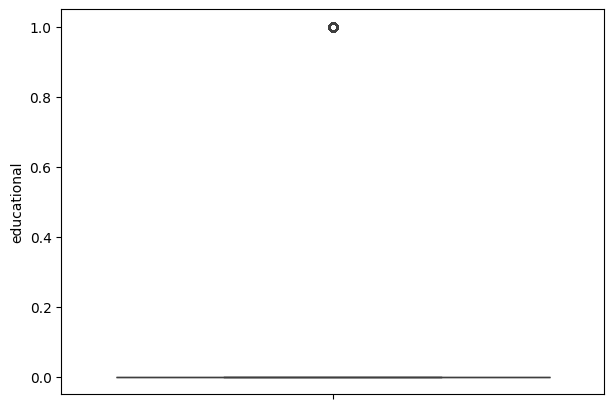

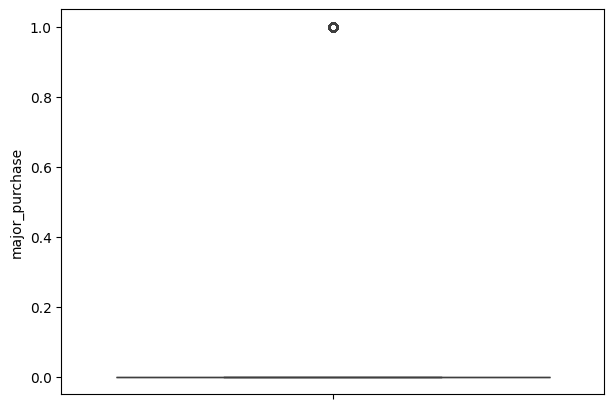

In [69]:
for col in sig_data:
     plt.figure(figsize=(7,5))
     sns.boxplot(sig_data[col])
     plt.show()

# Observations:
- the data looks imbalanced,but SMOT method gave lower accuracy, and I cannot drop some raws as data is already littel for a Deep Learning model.
- data has outliers, but when I used log transformation, I got less accuracy.
- the following architecture is the best I could manage to build after multiple other structures.

# Building the Model

In [23]:
# Splitting the dataset into the Training set and Test set
X = sig_data[['int.rate',
 'installment',
 'dti',
 'fico',
 'days.with.cr.line',
 'revol.util',
 'inq.last.6mths',
 'delinq.2yrs',
 'pub.rec',
 'not.fully.paid',
 'educational',
 'major_purchase']]
y = sig_data["credit.policy"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [117]:
y_train

,credit.policy
4247,1
8766,0
1509,1
6120,1
1069,1
...,...
7891,0
9225,0
4859,1
3264,1


In [25]:
# Feature Scaling
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [28]:
# Initialising the ANN
classifier = Sequential()

In [30]:
# Adding the input layer and the first hidden layer
classifier.add(Dense(32, kernel_initializer = 'he_uniform', activation = 'leaky_relu', input_dim = 12))


# Adding the second hidden layer
classifier.add(Dense(32, kernel_initializer = 'he_uniform', activation = 'leaky_relu'))

# Adding the third hidden layer
classifier.add(Dense(32, kernel_initializer = 'he_uniform', activation = 'leaky_relu'))
classifier.add(Dropout(0,3))

# Adding the fourth hidden layer
classifier.add(Dense(32, kernel_initializer = 'he_uniform', activation = 'leaky_relu'))
classifier.add(Dropout(0,3))

# Adding the fifth hidden layer
classifier.add(Dense(32, kernel_initializer = 'he_uniform', activation = 'leaky_relu'))
classifier.add(Dropout(0,3))

# Adding the sixth hidden layer
classifier.add(Dense(32, kernel_initializer = 'he_uniform', activation = 'leaky_relu'))


# Adding the output layer
classifier.add(Dense(1, kernel_initializer = 'glorot_uniform', activation = 'sigmoid'))

C:\Users\user\Anaconda\envs\cv\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [32]:
# Compiling the Model
classifier.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

In [ ]:
# Fitting the Model to the Training set
model_history = classifier.fit(X_train, y_train, validation_split = 0.15, batch_size = 16, epochs = 50)
# validation_split splits training data again to do the validation

Epoch 1/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.8346 - loss: 0.3990 - val_accuracy: 0.8878 - val_loss: 0.2965
Epoch 2/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8928 - loss: 0.2808 - val_accuracy: 0.9035 - val_loss: 0.2676
Epoch 3/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9068 - loss: 0.2443 - val_accuracy: 0.9139 - val_loss: 0.2365
Epoch 4/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9183 - loss: 0.2229 - val_accuracy: 0.9235 - val_loss: 0.2353
Epoch 5/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9195 - loss: 0.2084 - val_accuracy: 0.9304 - val_loss: 0.2110
Epoch 6/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9333 - loss: 0.1874 - val_accuracy: 0.9304 - val_loss: 0.2140
Epoch 7/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9381 - loss: 0.1782 - val_accuracy: 0.9322 - val_loss: 0.2006
Epoch 8/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9348 - loss: 0.1752 - val_accuracy: 0.

In [124]:
classifier.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_42 (Dense)                     │ (None, 32)                  │             416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_43 (Dense)                     │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_44 (Dense)                     │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_18 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_45 (Dense)                     │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_19 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_46 (Dense)                     │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_47 (Dense)                     │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_48 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 17,189 (67.15 KB)

 Trainable params: 5,729 (22.38 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 11,460 (44.77 KB)

In [125]:
# Making the prediction
y_pred = classifier.predict(X_test)
y_pred = (y_pred > 0.5)

60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [126]:
# Making the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
cm

array([[ 309,   70],
       [  41, 1496]])

In [127]:
# accuracy score
score = accuracy_score(y_pred, y_test)
score

0.9420668058455115

In [ ]:
class_report = classification_report(y_test, y_pred)
print(class_report)

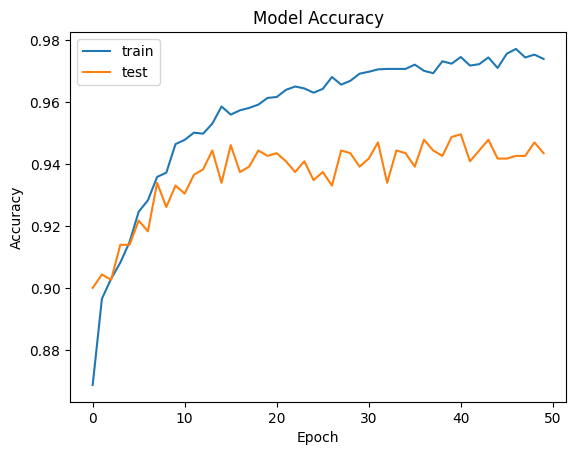

In [41]:
#summerize history of accuracy
plt.plot(model_history.history['accuracy'])
plt.plot(model_history.history['val_accuracy'])
plt.title("Model Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(['train', 'test'], loc='upper left')
plt.show()

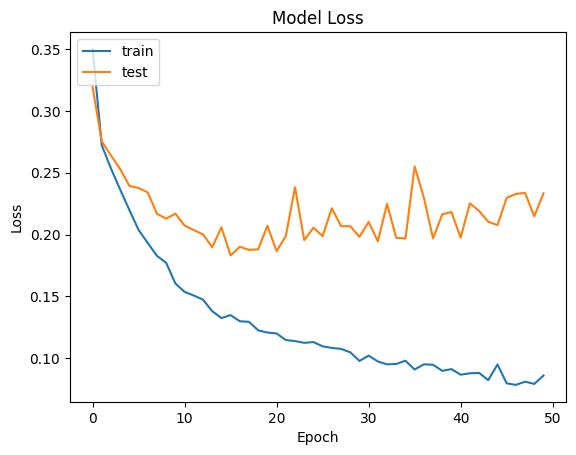

In [42]:
#summerize history of loss
plt.plot(model_history.history['loss'])
plt.plot(model_history.history['val_loss'])
plt.title("Model Loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(['train', 'test'], loc='upper left')
plt.show()